In [11]:
# Step 0.1: install the libraries (run once, then you can comment it out)
%pip install pandas numpy matplotlib scikit-learn keras tensorflow keras-tuner pyarrow huggingface_hub


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
# Step 0.2: imports + path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import keras

# set the random seed so the results are reproducible (same numbers every time you run)
keras.utils.set_random_seed(42)

# light theme for plots (marker reads screenshots)
plt.style.use("default")

In [13]:
# load dataset from Hugging Face Hub
base = "hf://datasets/Dingdong-Inc/FreshRetailNet-50K/"
train_df = pd.read_parquet(base + "data/train.parquet")
eval_df = pd.read_parquet(base + "data/eval.parquet")

print("train:", train_df.shape)
print("eval: ", eval_df.shape)
train_df.head()

train: (4500000, 19)
eval:  (350000, 19)


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,hours_sale,stock_hour6_22_cnt,hours_stock_status,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
0,0,0,0,5,6,65,38,2024-03-28,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, ...",0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,1.6999,15.48,73.54,1.97
1,0,0,0,5,6,65,38,2024-03-29,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,0,0,3.0190,15.08,76.56,1.71
2,0,0,0,5,6,65,38,2024-03-30,0.0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",0,"[1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",1.0,1,0,2.0942,15.91,76.47,1.73
3,0,0,0,5,6,65,38,2024-03-31,0.1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, ...",11,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, ...",1.0,1,0,1.5618,16.13,77.40,1.76
4,0,0,0,5,6,65,38,2024-04-01,0.2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.0, 0.0, ...",8,"[1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, ...",1.0,0,0,3.5386,15.37,78.26,1.25


## Step 2: clean + subset 
Each store-product pair is one time series: 90 days in `train` (2024-03-28 → 2024-06-25) and the next 7 days in `eval` (2024-06-26 → 2024-07-02).
We keep complete series so the daily order is never broken. 112 series × 90 days = 10,080 rows (≥ 10,000).

In [14]:
keys = ["store_id", "product_id"]

# cleaning
train_df = train_df.dropna().drop_duplicates(subset=keys + ["dt"])
eval_df = eval_df.dropna().drop_duplicates(subset=keys + ["dt"])

# keep only series with the full 90-day history
counts = train_df.groupby(keys).size()
full_series = counts[counts == 90].reset_index()[keys]

# pick 112 series at random -> 10,080 train rows
chosen = full_series.sample(n=112, random_state=42)

df = train_df.merge(chosen, on=keys)
test_df = eval_df.merge(chosen, on=keys)   # same series, the 7 days after -> time-based test set

for d in (df, test_df):
    d["dt"] = pd.to_datetime(d["dt"])
    d.sort_values(keys + ["dt"], inplace=True)
    d.reset_index(drop=True, inplace=True)

print("train subset:", df.shape)
print("test subset: ", test_df.shape)
print("series:", df.groupby(keys).ngroups)

train subset: (10080, 19)
test subset:  (784, 19)
series: 112


## Step 3: unpack the hourly list columns
`hours_sale` and `hours_stock_status` hold 24 values per row (one per hour). Expand them into separate columns.

In [15]:
def unpack_hours(d):
    sale_h = pd.DataFrame(d["hours_sale"].tolist(), index=d.index).add_prefix("sale_h")
    stock_h = pd.DataFrame(d["hours_stock_status"].tolist(), index=d.index).add_prefix("stock_h")
    return pd.concat([d.drop(columns=["hours_sale", "hours_stock_status"]), sale_h, stock_h], axis=1)

df = unpack_hours(df)
test_df = unpack_hours(test_df)
print(df.shape)
df.head()

(10080, 65)


,city_id,store_id,management_group_id,first_category_id,second_category_id,third_category_id,product_id,dt,sale_amount,stock_hour6_22_cnt,...,stock_h14,stock_h15,stock_h16,stock_h17,stock_h18,stock_h19,stock_h20,stock_h21,stock_h22,stock_h23
0,0,1,3,11,35,71,829,2024-03-28,0.2,5,...,0,0,0,1,1,1,1,1,1,1
1,0,1,3,11,35,71,829,2024-03-29,0.3,9,...,1,1,1,1,1,1,1,1,1,1
2,0,1,3,11,35,71,829,2024-03-30,0.3,0,...,0,0,0,0,0,0,0,0,0,0
3,0,1,3,11,35,71,829,2024-03-31,0.6,7,...,0,1,1,1,1,1,1,1,1,1
4,0,1,3,11,35,71,829,2024-04-01,0.5,3,...,0,0,0,0,0,1,1,1,1,1


## Step 4: first look at the data

In [16]:
df.info()
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10080 entries, 0 to 10079
Data columns (total 65 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   city_id              10080 non-null  int64         
 1   store_id             10080 non-null  int64         
 2   management_group_id  10080 non-null  int64         
 3   first_category_id    10080 non-null  int64         
 4   second_category_id   10080 non-null  int64         
 5   third_category_id    10080 non-null  int64         
 6   product_id           10080 non-null  int64         
 7   dt                   10080 non-null  datetime64[us]
 8   sale_amount          10080 non-null  float64       
 9   stock_hour6_22_cnt   10080 non-null  int32         
 10  discount             10080 non-null  float64       
 11  holiday_flag         10080 non-null  int32         
 12  activity_flag        10080 non-null  int32         
 13  precpt               10080 non-null  float

,count,mean,min,25%,50%,75%,max,std
city_id,10080.0,5.008929,0.0,0.0,3.0,12.0,17.0,5.808988
store_id,10080.0,416.267857,1.0,208.0,424.0,595.0,893.0,246.507989
management_group_id,10080.0,4.526786,0.0,3.0,6.0,6.0,6.0,2.048445
first_category_id,10080.0,15.625,0.0,7.75,16.0,21.0,31.0,8.962791
second_category_id,10080.0,44.839286,3.0,28.0,48.0,61.75,80.0,21.264938
...,...,...,...,...,...,...,...,...
stock_h19,10080.0,0.368651,0.0,0.0,0.0,1.0,1.0,0.482463
stock_h20,10080.0,0.390675,0.0,0.0,0.0,1.0,1.0,0.487926
stock_h21,10080.0,0.413591,0.0,0.0,0.0,1.0,1.0,0.492501
stock_h22,10080.0,0.426786,0.0,0.0,0.0,1.0,1.0,0.494635


In [17]:
# missing values and number of unique values per ID column
print(df.isna().sum().sum(), "missing values")
df[["city_id", "store_id", "management_group_id", "first_category_id",
    "second_category_id", "third_category_id", "product_id"]].nunique()

0 missing values


city_id                 15
store_id               106
management_group_id      6
first_category_id       19
second_category_id      34
third_category_id       65
product_id              91
dtype: int64

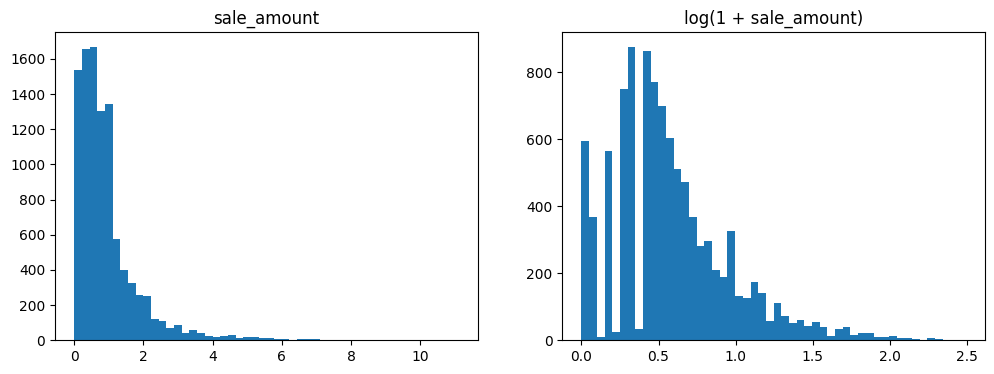

In [18]:
# distribution of daily sales (target candidate for regression)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["sale_amount"], bins=50)
ax[0].set_title("sale_amount")
ax[1].hist(np.log1p(df["sale_amount"]), bins=50)
ax[1].set_title("log(1 + sale_amount)")
plt.show()

rows with any stockout: 44.9 %


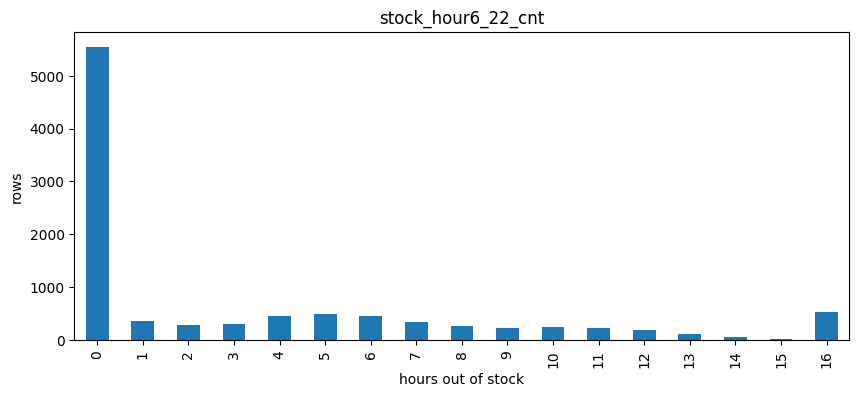

In [19]:
# stockouts: hours out of stock (6:00-22:00) per day (target candidate for classification)
print("rows with any stockout:", round((df["stock_hour6_22_cnt"] > 0).mean() * 100, 1), "%")
df["stock_hour6_22_cnt"].value_counts().sort_index().plot(kind="bar", figsize=(10, 4))
plt.title("stock_hour6_22_cnt")
plt.xlabel("hours out of stock")
plt.ylabel("rows")
plt.show()

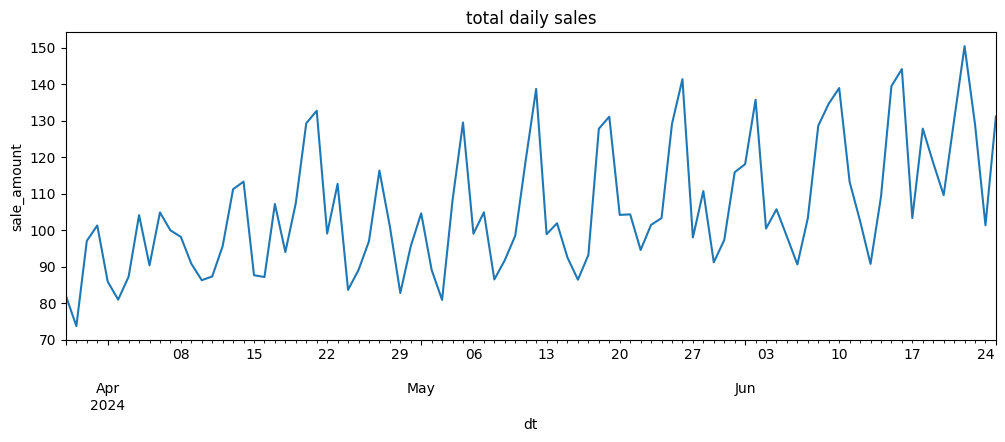

In [20]:
# total sales per day across the subset
df.groupby("dt")["sale_amount"].sum().plot(figsize=(12, 4))
plt.title("total daily sales")
plt.ylabel("sale_amount")
plt.show()

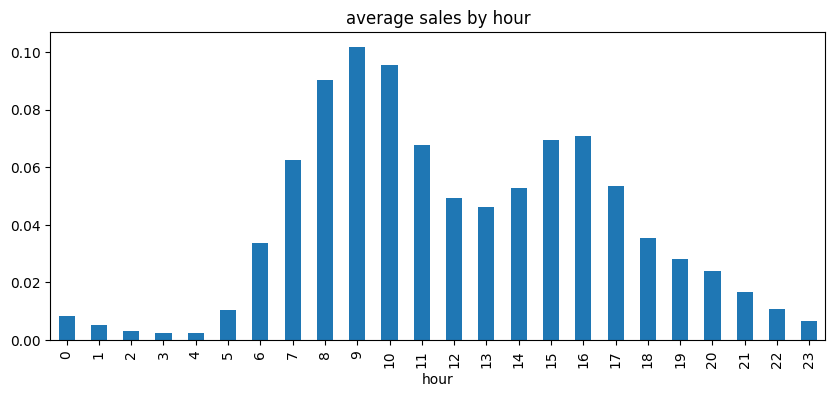

In [21]:
# average sales by hour of day
sale_cols = [f"sale_h{i}" for i in range(24)]
df[sale_cols].mean().set_axis(range(24)).plot(kind="bar", figsize=(10, 4))
plt.title("average sales by hour")
plt.xlabel("hour")
plt.show()

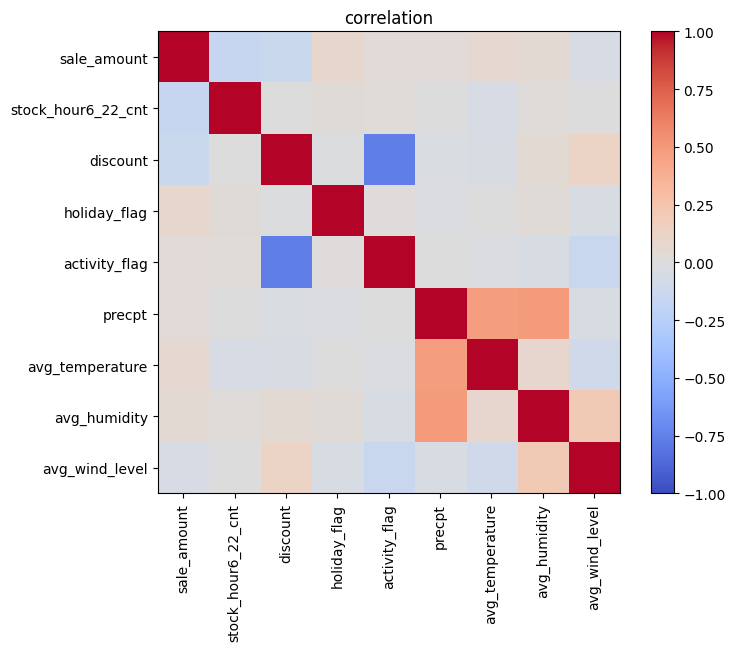

,sale_amount,stock_hour6_22_cnt,discount,holiday_flag,activity_flag,precpt,avg_temperature,avg_humidity,avg_wind_level
sale_amount,1.00,-0.15,-0.13,0.09,0.03,0.03,0.06,0.05,-0.05
stock_hour6_22_cnt,-0.15,1.00,-0.00,0.03,0.02,-0.01,-0.05,0.02,-0.00
discount,-0.13,-0.00,1.00,-0.01,-0.76,-0.03,-0.04,0.05,0.12
holiday_flag,0.09,0.03,-0.01,1.00,0.01,-0.02,-0.00,0.02,-0.04
activity_flag,0.03,0.02,-0.76,0.01,1.00,-0.00,-0.02,-0.04,-0.14
precpt,0.03,-0.01,-0.03,-0.02,-0.00,1.00,0.47,0.49,-0.05
avg_temperature,0.06,-0.05,-0.04,-0.00,-0.02,0.47,1.00,0.08,-0.10
avg_humidity,0.05,0.02,0.05,0.02,-0.04,0.49,0.08,1.00,0.20
avg_wind_level,-0.05,-0.00,0.12,-0.04,-0.14,-0.05,-0.10,0.20,1.00


In [22]:
# correlation between the numeric features
num_cols = ["sale_amount", "stock_hour6_22_cnt", "discount", "holiday_flag", "activity_flag",
            "precpt", "avg_temperature", "avg_humidity", "avg_wind_level"]
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=90)
plt.yticks(range(len(num_cols)), num_cols)
plt.title("correlation")
plt.show()
corr.round(2)